# Cell 1 — Import required libraries

In [1]:
# Import utilities for file management and warning control.
import os
import glob
import zipfile
import warnings

# Import data analysis and visualization libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for data splitting and cross-validation.
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV

# Import preprocessing tools for numeric and categorical data.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Import classification algorithms and evaluation metrics.
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# Configure visualization style and reproducible experiments.
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

# Set a fixed random seed for reproducibility.
RANDOM_STATE = 42

print("Basic libraries imported successfully.")

Basic libraries imported successfully.


# Cell 2 — Install XGBoost and imbalanced-learn

In [2]:
# Install XGBoost for gradient boosting and imbalanced-learn for SMOTE.
%pip -q install xgboost imbalanced-learn

# Import the SMOTE technique and XGBoost classifier.
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

print("XGBoost and imbalanced-learn are ready.")

XGBoost and imbalanced-learn are ready.


# Cell 3 — Mount Google Drive

In [3]:
# Import Google Colab's Google Drive integration.
from google.colab import drive

# Mount Drive to access the uploaded dataset and save project outputs.
drive.mount("/content/drive")

# Create a dedicated folder for the churn project results.
OUTPUT_DIR = "/content/drive/MyDrive/Customer_Churn_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Display the folder where outputs will be stored.
print("Output folder:", OUTPUT_DIR)

Mounted at /content/drive
Output folder: /content/drive/MyDrive/Customer_Churn_Results


# Cell 4 — Find and load the dataset

In [4]:
# Search Google Drive for the uploaded Telco customer churn CSV file.
csv_files = glob.glob(
    "/content/drive/MyDrive/**/Telco-Customer-Churn.csv",
    recursive=True
)

# Stop execution if the dataset cannot be located.
if not csv_files:
    raise FileNotFoundError(
        "Telco-Customer-Churn.csv was not found in Google Drive. "
        "Check the file name or set DATA_PATH manually."
    )

# Select the first matching dataset path.
DATA_PATH = csv_files[0]

# Load the CSV dataset into a pandas DataFrame.
df = pd.read_csv(DATA_PATH)

# Display the dataset path, dimensions, and first five rows.
print("Dataset path:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset path: /content/drive/MyDrive/Telco-Customer-Churn.csv
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Cell 5 — Inspect the dataset

In [5]:
# Display column names and their data types.
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

# Count missing values in each column.
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Count"))

# Check for duplicate records.
print("\nDuplicate rows:", df.duplicated().sum())

# Display descriptive statistics for numeric and categorical columns.
display(df.describe(include="all").T)

# Display the original churn target distribution.
if "Churn" in df.columns:
    print("\nOriginal churn distribution:")
    display(df["Churn"].value_counts(dropna=False).to_frame("Count"))

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

,Missing Count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Original churn distribution:


,Count
Churn,
No,5174
Yes,1869


# Cell 6 — Clean the data and convert TotalCharges

In [6]:
# Remove extra spaces from column names.
df.columns = df.columns.str.strip()

# Remove duplicate records to avoid repeated observations.
df = df.drop_duplicates().copy()

# Confirm that the expected target column exists.
if "Churn" not in df.columns:
    raise ValueError(
        f"'Churn' target column was not found. Columns: {df.columns.tolist()}"
    )

# Convert TotalCharges to numeric; blank or invalid entries become NaN.
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"].astype(str).str.strip(),
        errors="coerce"
    )

# Remove rows with a missing target label.
df = df.dropna(subset=["Churn"]).copy()

# Remove rows with unexpected target labels.
df = df[df["Churn"].isin(["Yes", "No"])].copy()

# Convert the target into binary labels: Yes = 1 and No = 0.
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)

# Drop customerID because it is an identifier rather than a predictive feature.
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# Display the cleaned data and remaining missing values.
print("Cleaned dataset shape:", df.shape)
print("\nMissing values after TotalCharges conversion:")
display(df.isnull().sum().to_frame("Missing Count"))
display(df.head())

Cleaned dataset shape: (7043, 20)

Missing values after TotalCharges conversion:


,Missing Count
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


# Cell 7 — Visualize class imbalance

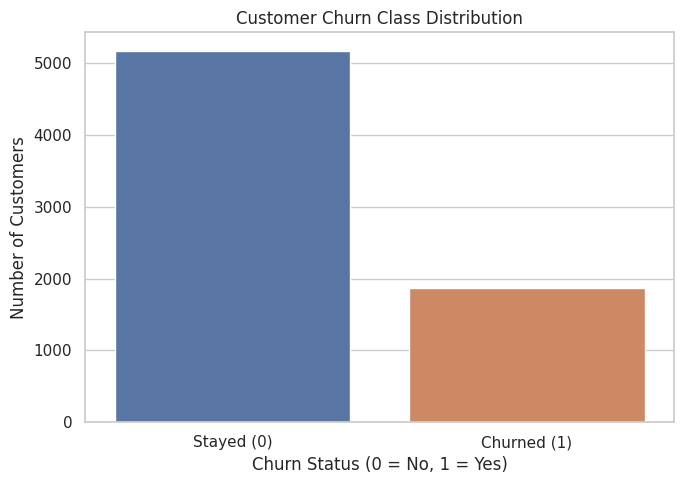

Class percentages:


,Percentage
Churn,
0,73.46
1,26.54


In [7]:
# Count customers who churned and customers who stayed.
class_counts = df["Churn"].value_counts().sort_index()

# Convert binary labels into readable category names for the plot.
class_labels = ["Stayed (0)", "Churned (1)"]

# Plot the distribution of the target classes.
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn", hue="Churn", order=[0, 1], legend=False)

# Add chart labels and title.
plt.title("Customer Churn Class Distribution")
plt.xlabel("Churn Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], class_labels)
plt.tight_layout()

# Save the chart to Google Drive.
plt.savefig(f"{OUTPUT_DIR}/01_class_distribution.png", dpi=300)
plt.show()

# Print the percentage of each class.
print("Class percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

# Cell 8 — Separate features and target

In [8]:
# Separate the input features from the target label.
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Identify numeric features automatically.
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

# Identify categorical features automatically.
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Display the detected feature groups.
print("Numeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Split the dataset while preserving the churn ratio in both subsets.
# The test set will remain untouched during cross-validation and model tuning.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Display the sizes and churn percentages of each subset.
print("\nTraining set size:", X_train.shape)
print("Test set size:", X_test.shape)
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Test churn rate:", round(y_test.mean() * 100, 2), "%")

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Training set size: (5634, 19)
Test set size: (1409, 19)
Training churn rate: 26.54 %
Test churn rate: 26.54 %


# Cell 9 — Preprocess numeric and categorical features

In [9]:
# Impute missing numeric values with the median and standardize numeric features.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Impute missing categorical values and one-hot encode the categories.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing pipeline to each feature group.
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


# Cell 10 — Create the Random Forest model with SMOTE

In [10]:
# Build a pipeline that preprocesses data, applies SMOTE, and trains Random Forest.
# SMOTE is inside the pipeline so it is applied only to training folds during CV.
rf_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Train the Random Forest model on the training set.
rf_pipeline.fit(X_train, y_train)

# Obtain churn probabilities for the positive class.
rf_probabilities = rf_pipeline.predict_proba(X_test)[:, 1]

# Convert probabilities to binary predictions using the default 0.50 threshold.
rf_predictions = (rf_probabilities >= 0.50).astype(int)

print("Random Forest training completed.")

Random Forest training completed.


# Cell 11 — Create the XGBoost model with SMOTE

In [11]:
# Build a pipeline that preprocesses features, applies SMOTE, and trains XGBoost.
xgb_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Train the XGBoost classifier on the training data.
xgb_pipeline.fit(X_train, y_train)

# Obtain predicted probabilities for customers likely to churn.
xgb_probabilities = xgb_pipeline.predict_proba(X_test)[:, 1]

# Apply the default 0.50 probability threshold for binary predictions.
xgb_predictions = (xgb_probabilities >= 0.50).astype(int)

print("XGBoost training completed.")

XGBoost training completed.


# Cell 12 — Evaluate both models using 5-fold cross-validation

In [12]:
# Use stratified folds to preserve the churn ratio in each validation fold.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Define the evaluation metrics used during cross-validation.
scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall"
}

# Evaluate Random Forest; preprocessing and SMOTE occur inside each training fold.
rf_cv = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Evaluate XGBoost using the same cross-validation folds.
xgb_cv = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Summarize mean and standard deviation for each metric.
cv_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Mean ROC-AUC": rf_cv["test_roc_auc"].mean(),
        "ROC-AUC Std": rf_cv["test_roc_auc"].std(),
        "Mean F1": rf_cv["test_f1"].mean(),
        "Mean Precision": rf_cv["test_precision"].mean(),
        "Mean Recall": rf_cv["test_recall"].mean()
    },
    {
        "Model": "XGBoost",
        "Mean ROC-AUC": xgb_cv["test_roc_auc"].mean(),
        "ROC-AUC Std": xgb_cv["test_roc_auc"].std(),
        "Mean F1": xgb_cv["test_f1"].mean(),
        "Mean Precision": xgb_cv["test_precision"].mean(),
        "Mean Recall": xgb_cv["test_recall"].mean()
    }
])

# Display and save the cross-validation results.
display(cv_results.round(4))
cv_results.to_csv(f"{OUTPUT_DIR}/cross_validation_results.csv", index=False)

,Model,Mean ROC-AUC,ROC-AUC Std,Mean F1,Mean Precision,Mean Recall
0,Random Forest,0.8174,0.0121,0.5644,0.5865,0.5445
1,XGBoost,0.8439,0.0096,0.6150,0.6110,0.6201


# Cell 13 — Tune Random Forest with GridSearchCV

In [13]:
# Define a compact hyperparameter grid for Random Forest.
rf_param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [None, 12],
    "classifier__min_samples_leaf": [1, 3]
}

# Search for the best Random Forest configuration using training data only.
rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1
)

# Fit each parameter configuration and select the best by mean CV ROC-AUC.
rf_search.fit(X_train, y_train)

# Retrieve the best fitted Random Forest model.
best_rf = rf_search.best_estimator_

# Display the best parameters and cross-validation ROC-AUC.
print("Best Random Forest parameters:", rf_search.best_params_)
print("Best Random Forest CV ROC-AUC:", round(rf_search.best_score_, 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Random Forest parameters: {'classifier__max_depth': 12, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 400}
Best Random Forest CV ROC-AUC: 0.8395


# Cell 14 — Tune XGBoost with GridSearchCV

In [14]:
# Define a compact hyperparameter grid for XGBoost.
xgb_param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.03, 0.1]
}

# Search for the best XGBoost configuration using stratified cross-validation.
xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1
)

# Fit and tune XGBoost using only the training data.
xgb_search.fit(X_train, y_train)

# Retrieve the best fitted XGBoost model.
best_xgb = xgb_search.best_estimator_

# Display the selected parameters and CV ROC-AUC.
print("Best XGBoost parameters:", xgb_search.best_params_)
print("Best XGBoost CV ROC-AUC:", round(xgb_search.best_score_, 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best XGBoost parameters: {'classifier__learning_rate': 0.03, 'classifier__max_depth': 3, 'classifier__n_estimators': 200}
Best XGBoost CV ROC-AUC: 0.8467


# Cell 15 — Final test-set evaluation

In [15]:
# Generate churn probabilities from each tuned model on the untouched test set.
rf_probabilities = best_rf.predict_proba(X_test)[:, 1]
xgb_probabilities = best_xgb.predict_proba(X_test)[:, 1]

# Apply the default threshold to generate binary class predictions.
rf_predictions = (rf_probabilities >= 0.50).astype(int)
xgb_predictions = (xgb_probabilities >= 0.50).astype(int)

# Define a helper function for calculating the required classification metrics.
def evaluate_classifier(model_name, y_true, y_pred, y_prob):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

# Calculate the metrics for the tuned models.
test_results = pd.DataFrame([
    evaluate_classifier(
        "Random Forest", y_test, rf_predictions, rf_probabilities
    ),
    evaluate_classifier(
        "XGBoost", y_test, xgb_predictions, xgb_probabilities
    )
])

# Rank models by ROC-AUC, where higher values indicate better ranking ability.
test_results = test_results.sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)

# Display and save the test-set metrics.
display(test_results.round(4))
test_results.to_csv(f"{OUTPUT_DIR}/test_set_model_comparison.csv", index=False)

# Report whether each model meets the project's ROC-AUC goal.
for _, row in test_results.iterrows():
    status = "Goal achieved" if row["ROC-AUC"] >= 0.80 else "Goal not yet achieved"
    print(f"{row['Model']}: ROC-AUC = {row['ROC-AUC']:.4f} — {status}")

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.7764,0.5608,0.7273,0.6333,0.8432
1,Random Forest,0.7700,0.5558,0.6658,0.6058,0.8350


XGBoost: ROC-AUC = 0.8432 — Goal achieved
Random Forest: ROC-AUC = 0.8350 — Goal achieved


# Cell 16 — Plot ROC-AUC curves

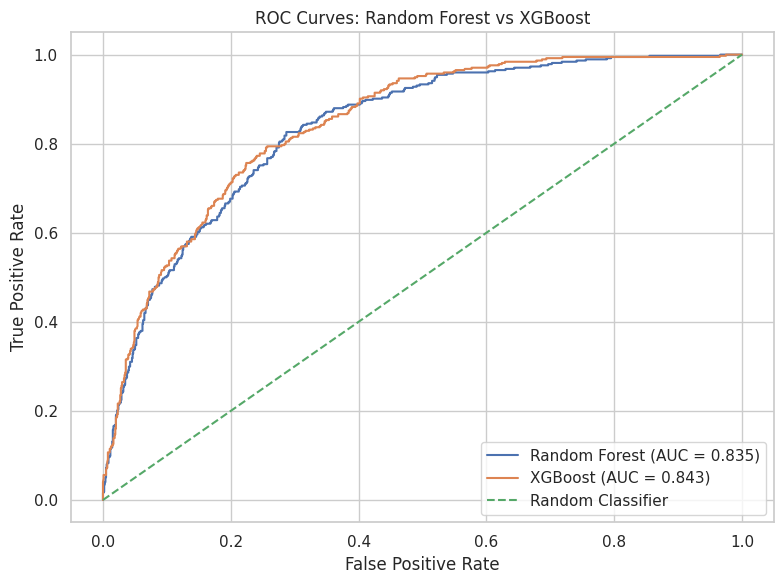

In [16]:
# Calculate ROC curve coordinates for Random Forest.
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)
rf_auc = roc_auc_score(y_test, rf_probabilities)

# Calculate ROC curve coordinates for XGBoost.
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probabilities)
xgb_auc = roc_auc_score(y_test, xgb_probabilities)

# Plot both ROC curves on the same figure.
plt.figure(figsize=(8, 6))
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")
plt.plot(xgb_fpr, xgb_tpr, label=f"XGBoost (AUC = {xgb_auc:.3f})")

# Add the diagonal reference line representing random ranking.
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

# Label the axes and display the legend.
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Random Forest vs XGBoost")
plt.legend(loc="lower right")
plt.tight_layout()

# Save and display the ROC curve plot.
plt.savefig(f"{OUTPUT_DIR}/02_roc_curves.png", dpi=300)
plt.show()

# Cell 17 — Confusion matrices

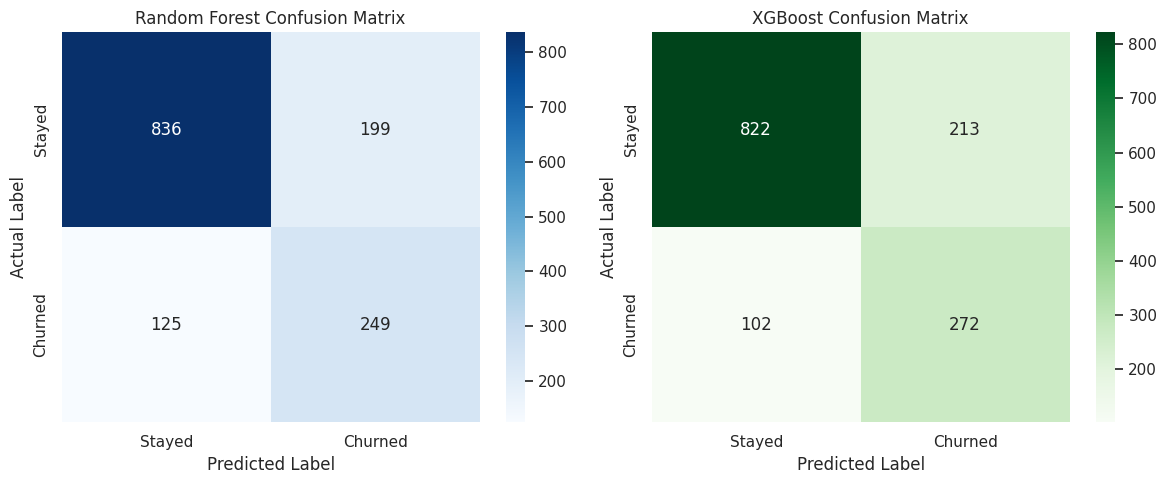

In [17]:
# Compute confusion matrices using the default 0.50 probability threshold.
rf_cm = confusion_matrix(y_test, rf_predictions, labels=[0, 1])
xgb_cm = confusion_matrix(y_test, xgb_predictions, labels=[0, 1])

# Create side-by-side confusion matrix plots.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Visualize Random Forest classification results.
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"],
    ax=axes[0]
)
axes[0].set_title("Random Forest Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# Visualize XGBoost classification results.
sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"],
    ax=axes[1]
)
axes[1].set_title("XGBoost Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

# Save and display the comparison figure.
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/03_confusion_matrices.png", dpi=300)
plt.show()

# Cell 18 — Classification reports

In [18]:
# Print precision, recall, F1-score, and support for each class.
print("RANDOM FOREST CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        rf_predictions,
        labels=[0, 1],
        target_names=["Stayed", "Churned"],
        zero_division=0
    )
)

print("\nXGBOOST CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        xgb_predictions,
        labels=[0, 1],
        target_names=["Stayed", "Churned"],
        zero_division=0
    )
)

# Save both reports to a text file for the final submission.
with open(
    f"{OUTPUT_DIR}/classification_reports.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write("RANDOM FOREST CLASSIFICATION REPORT\n")
    file.write(
        classification_report(
            y_test, rf_predictions,
            target_names=["Stayed", "Churned"],
            zero_division=0
        )
    )
    file.write("\n\nXGBOOST CLASSIFICATION REPORT\n")
    file.write(
        classification_report(
            y_test, xgb_predictions,
            target_names=["Stayed", "Churned"],
            zero_division=0
        )
    )

print("Classification reports saved.")

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Stayed       0.87      0.81      0.84      1035
     Churned       0.56      0.67      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409


XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Stayed       0.89      0.79      0.84      1035
     Churned       0.56      0.73      0.63       374

    accuracy                           0.78      1409
   macro avg       0.73      0.76      0.74      1409
weighted avg       0.80      0.78      0.78      1409

Classification reports saved.


# Cell 19 — Extract feature names after OneHotEncoder

In [19]:
# Retrieve the fitted preprocessing transformer from the tuned Random Forest pipeline.
fitted_preprocessor = best_rf.named_steps["preprocessor"]

# Extract feature names created by numeric and categorical preprocessing.
feature_names = fitted_preprocessor.get_feature_names_out()

# Display the number and names of transformed features.
print("Number of transformed features:", len(feature_names))
print("First 20 transformed features:")
print(feature_names[:20])

Number of transformed features: 45
First 20 transformed features:
['numeric__SeniorCitizen' 'numeric__tenure' 'numeric__MonthlyCharges'
 'numeric__TotalCharges' 'categorical__gender_Female'
 'categorical__gender_Male' 'categorical__Partner_No'
 'categorical__Partner_Yes' 'categorical__Dependents_No'
 'categorical__Dependents_Yes' 'categorical__PhoneService_No'
 'categorical__PhoneService_Yes' 'categorical__MultipleLines_No'
 'categorical__MultipleLines_No phone service'
 'categorical__MultipleLines_Yes' 'categorical__InternetService_DSL'
 'categorical__InternetService_Fiber optic'
 'categorical__InternetService_No' 'categorical__OnlineSecurity_No'
 'categorical__OnlineSecurity_No internet service']


# Cell 20 — Top 10 feature importance: Random Forest

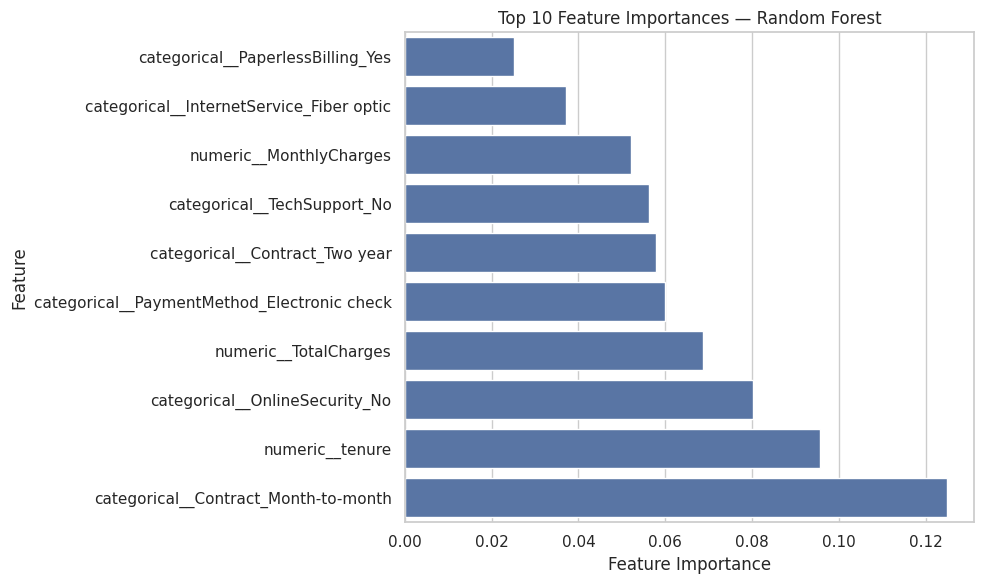

In [20]:
# Extract feature importance scores from the tuned Random Forest classifier.
rf_importances = best_rf.named_steps["classifier"].feature_importances_

# Pair each importance score with its transformed feature name.
rf_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importances
})

# Sort features by importance and select the ten highest-scoring features.
rf_top10 = rf_importance_df.sort_values(
    "Importance", ascending=False
).head(10)

# Plot the top ten Random Forest features.
plt.figure(figsize=(10, 6))
sns.barplot(
    data=rf_top10.sort_values("Importance"),
    x="Importance",
    y="Feature"
)

# Add the chart title and axis labels.
plt.title("Top 10 Feature Importances — Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

# Save and display the feature importance chart.
plt.savefig(f"{OUTPUT_DIR}/04_rf_top10_feature_importance.png", dpi=300)
plt.show()

# Save the complete feature importance table.
rf_importance_df.sort_values(
    "Importance", ascending=False
).to_csv(f"{OUTPUT_DIR}/rf_feature_importance.csv", index=False)

# Cell 21 — Top 10 feature importance: XGBoost

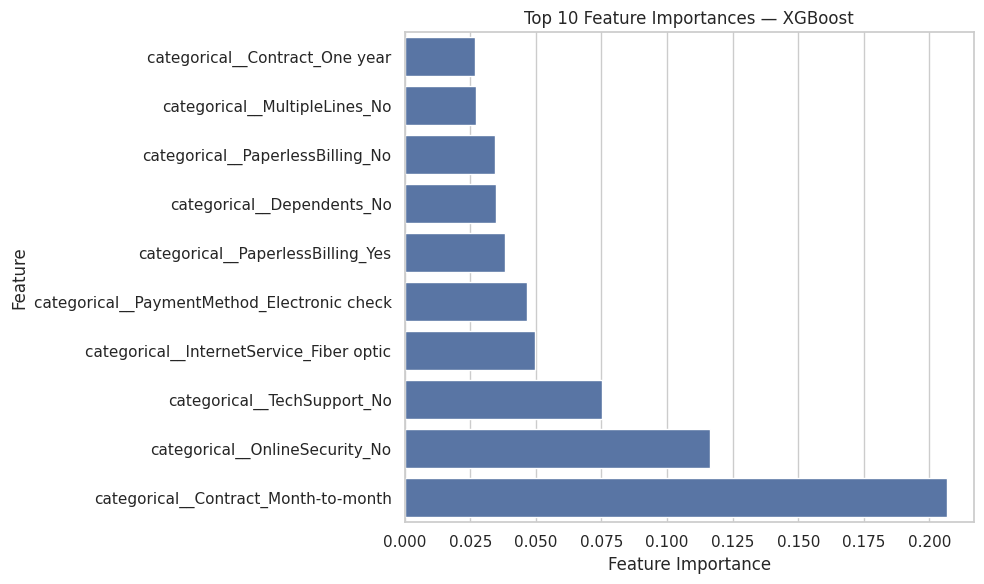

In [21]:
# Extract feature importance scores from the tuned XGBoost classifier.
xgb_importances = best_xgb.named_steps["classifier"].feature_importances_

# Pair each transformed feature name with its XGBoost importance score.
xgb_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_importances
})

# Select the ten features with the highest importance scores.
xgb_top10 = xgb_importance_df.sort_values(
    "Importance", ascending=False
).head(10)

# Plot the ten most important XGBoost features.
plt.figure(figsize=(10, 6))
sns.barplot(
    data=xgb_top10.sort_values("Importance"),
    x="Importance",
    y="Feature"
)

# Add the chart title and axis labels.
plt.title("Top 10 Feature Importances — XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

# Save and display the XGBoost feature importance chart.
plt.savefig(f"{OUTPUT_DIR}/05_xgb_top10_feature_importance.png", dpi=300)
plt.show()

# Save all XGBoost feature importance scores.
xgb_importance_df.sort_values(
    "Importance", ascending=False
).to_csv(f"{OUTPUT_DIR}/xgb_feature_importance.csv", index=False)

# Cell 22 — Save test predictions

In [22]:
# Create a results table containing actual labels and model probabilities.
prediction_results = pd.DataFrame({
    "Actual_Churn": np.asarray(y_test),
    "RF_Probability": rf_probabilities,
    "RF_Prediction": rf_predictions,
    "XGB_Probability": xgb_probabilities,
    "XGB_Prediction": xgb_predictions
})

# Save the predictions to Google Drive for further analysis.
prediction_results.to_csv(
    f"{OUTPUT_DIR}/test_set_predictions.csv",
    index=False
)

# Display a sample of the saved prediction results.
display(prediction_results.head(10))

print("Test predictions saved successfully.")

,Actual_Churn,RF_Probability,RF_Prediction,XGB_Probability,XGB_Prediction
0,0,0.009278,0,0.041367,0
1,0,0.709635,1,0.761672,1
2,0,0.060848,0,0.059300,0
3,0,0.315311,0,0.458993,0
4,0,0.033765,0,0.038683,0
5,0,0.759616,1,0.675097,1
6,0,0.478926,0,0.541559,1
7,0,0.158489,0,0.160737,0
8,0,0.002930,0,0.016425,0
9,1,0.607773,1,0.605324,1


Test predictions saved successfully.


# Cell 23 — Save the final project report

In [23]:
# Select the best model according to test-set ROC-AUC for reporting.
best_model_name = test_results.iloc[0]["Model"]
best_auc = test_results.iloc[0]["ROC-AUC"]

# Create a text report containing dataset details, metrics, and tuned parameters.
report_path = f"{OUTPUT_DIR}/final_project_report.txt"

with open(report_path, "w", encoding="utf-8") as file:
    # Write the project title and dataset summary.
    file.write("PREDICTIVE CUSTOMER CHURN CLASSIFICATION\n")
    file.write("Random Forest and XGBoost with SMOTE\n")
    file.write("=" * 50 + "\n\n")
    file.write(f"Dataset shape after cleaning: {df.shape}\n")
    file.write(f"Training samples: {len(X_train)}\n")
    file.write(f"Test samples: {len(X_test)}\n")
    file.write(f"Target: Churn (1 = Yes, 0 = No)\n\n")

    # Write cross-validation results.
    file.write("CROSS-VALIDATION RESULTS\n")
    file.write(cv_results.to_string(index=False))
    file.write("\n\n")

    # Write test-set evaluation metrics.
    file.write("TEST-SET RESULTS\n")
    file.write(test_results.to_string(index=False))
    file.write("\n\n")

    # Write the best hyperparameters for each model.
    file.write(f"Best Random Forest parameters: {rf_search.best_params_}\n")
    file.write(f"Best XGBoost parameters: {xgb_search.best_params_}\n\n")

    # Record the top model and whether it met the ROC-AUC target.
    file.write(f"Best model by test ROC-AUC: {best_model_name}\n")
    file.write(f"Best test ROC-AUC: {best_auc:.4f}\n")
    file.write(f"ROC-AUC >= 0.80: {best_auc >= 0.80}\n")

# Confirm that the report has been saved.
print("Final report saved:", report_path)

Final report saved: /content/drive/MyDrive/Customer_Churn_Results/final_project_report.txt


# Cell 24 — Create a ZIP of all outputs and download it

In [24]:
# Define the ZIP archive path in the temporary Colab storage.
zip_path = "/content/Customer_Churn_Results.zip"

# Include every saved result, CSV, text report, and visualization in the ZIP.
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for root, _, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:
            # Build the complete path to each file.
            full_path = os.path.join(root, filename)

            # Use a relative path to keep the archive organized.
            relative_path = os.path.relpath(full_path, OUTPUT_DIR)

            # Add the file to the archive.
            zip_file.write(full_path, arcname=relative_path)

# Display the ZIP archive path.
print("ZIP archive created:", zip_path)

# Download the ZIP archive to your computer.
from google.colab import files
files.download(zip_path)

ZIP archive created: /content/Customer_Churn_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Cell 25 — Final verification

In [25]:
# List the generated files in the Google Drive output folder.
print("Generated project files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

# Display the final test-set comparison.
print("\nFinal model comparison:")
display(test_results.round(4))

# Show which model achieved the highest ROC-AUC.
print("\nBest model by test ROC-AUC:", best_model_name)
print(f"Best ROC-AUC: {best_auc:.4f}")

# Confirm whether the target ROC-AUC threshold was reached.
if best_auc >= 0.80:
    print("ROC-AUC target of 0.80 or higher was achieved.")
else:
    print("ROC-AUC target was not achieved; consider further tuning.")

print("\nCustomer churn classification project completed.")

Generated project files:
- 01_class_distribution.png
- 02_roc_curves.png
- 03_confusion_matrices.png
- 04_rf_top10_feature_importance.png
- 05_xgb_top10_feature_importance.png
- classification_reports.txt
- cross_validation_results.csv
- final_project_report.txt
- rf_feature_importance.csv
- test_set_model_comparison.csv
- test_set_predictions.csv
- xgb_feature_importance.csv

Final model comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.7764,0.5608,0.7273,0.6333,0.8432
1,Random Forest,0.7700,0.5558,0.6658,0.6058,0.8350



Best model by test ROC-AUC: XGBoost
Best ROC-AUC: 0.8432
ROC-AUC target of 0.80 or higher was achieved.

Customer churn classification project completed.
